### Your name:

<pre> Shamir Alavi </pre>

### Collaborators:

<pre> None </pre>


# Assignment for Module 4: Clustering

## Description

In this assignment you will study the electric demand (power) of clients in Portugal, during 2013 and 2014.

The data$^1$ available contains 370 time series, corresponding to the electric demand$^2$ for 370 clients, between 2011 and 2014. 

In this guided exercise you will use clustering techniques to understand the typical behaviour during 2013-2014.

#### 1. Data:
https://archive.ics.uci.edu/ml/datasets/ElectricityLoadDiagrams20112014#

#### 2. Electric Demand:
http://www.think-energy.net/KWvsKWH.htm


## Data Preparation

Start by downloading the data to a local directory and modify the "pathToFile" and "fileName" variables, if needed

In [1]:
import os
import fileinput
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
random.seed(42)

In [2]:
DATA_PATH = os.path.join('..', 'data')

def load_usage_data(data_path=DATA_PATH):
    file_path = os.path.join(data_path, "LD2011_2014.txt")
    
    with fileinput.FileInput(file_path, inplace=True, backup='.bak') as file:
        for line in file:
            print(line.replace(",", "."), end='')
    
    return pd.read_csv(file_path, sep=";", index_col=0)
    
data = load_usage_data()

### Quick data inspection

In [7]:
data.head(2)

,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
data.tail(2)

,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
2014-12-31 23:45:00,1.269036,21.337127,1.737619,166.666667,85.365854,285.714286,10.17524,225.589226,64.685315,72.043011,...,246.252677,28000.0,1443.037975,909.090909,26.075619,4.095963,664.618086,146.911519,646.627566,6540.540541
2015-01-01 00:00:00,2.538071,19.914651,1.737619,178.861789,84.146341,279.761905,10.17524,249.158249,62.937063,69.892473,...,188.436831,27800.0,1409.282700,954.545455,27.379400,4.095963,628.621598,131.886477,673.020528,7135.135135


In [9]:
data.shape

(140256, 370)

#### As can be seen, the dataframe contains a row for each interval of 15 minutes between Jan 1, 2011 to Dec 31 2014. There are 370 columns corresponding 370 clients. The dataframe is indexed by the timestamp.

Since the frequency is 15 minutes, each day provides $24\times 4 = 96$ datapoints, which multiplied by 365 days and 4 years (plus 1 day in Feb 29, 2012) gives: $96 \times 365 \times 4 + 96 = 140256$, as observed in data.shape

In [10]:
data.info()

<class 'pandas.DataFrame'>
Index: 140256 entries, 2011-01-01 00:15:00 to 2015-01-01 00:00:00
Columns: 370 entries, MT_001 to MT_370
dtypes: float64(370)
memory usage: 397.0+ MB


In [11]:
data.describe()

,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
count,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,...,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000
mean,3.970785,20.768480,2.918308,82.184490,37.240309,141.227385,4.521338,191.401476,39.975354,42.205152,...,218.213701,37607.987537,1887.427366,2940.031734,65.413150,9.269709,424.262904,94.704717,625.251734,8722.355145
std,5.983965,13.272415,11.014456,58.248392,26.461327,98.439984,6.485684,121.981187,29.814595,33.401251,...,204.833532,38691.954832,1801.486488,2732.251967,65.007818,10.016782,274.337122,80.297301,380.656042,9195.155777
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.844950,0.000000,36.585366,15.853659,71.428571,0.565291,111.111111,13.986014,9.677419,...,5.710207,0.000000,0.000000,0.000000,13.037810,0.000000,0.000000,30.050083,83.944282,0.000000
50%,1.269036,24.893314,1.737619,87.398374,39.024390,157.738095,2.826456,222.222222,40.209790,40.860215,...,131.334761,24100.000000,1050.632911,2136.363636,31.290743,7.021650,525.899912,76.794658,758.064516,0.000000
75%,2.538071,29.871977,1.737619,115.853659,54.878049,205.357143,4.522329,279.461279,57.692308,61.290323,...,403.283369,54800.000000,3312.236287,5363.636364,108.213820,11.702750,627.743635,151.919866,875.366569,17783.783784
max,48.223350,115.220484,151.172893,321.138211,150.000000,535.714286,44.657999,552.188552,157.342657,198.924731,...,852.962170,192800.000000,7751.054852,12386.363636,335.071708,60.269163,1138.718174,362.270451,1549.120235,30918.918919


In [13]:
data.columns

Index(['MT_001', 'MT_002', 'MT_003', 'MT_004', 'MT_005', 'MT_006', 'MT_007',
       'MT_008', 'MT_009', 'MT_010',
       ...
       'MT_361', 'MT_362', 'MT_363', 'MT_364', 'MT_365', 'MT_366', 'MT_367',
       'MT_368', 'MT_369', 'MT_370'],
      dtype='str', length=370)

### Plot the 2 days of 2012 for the first 2 clients

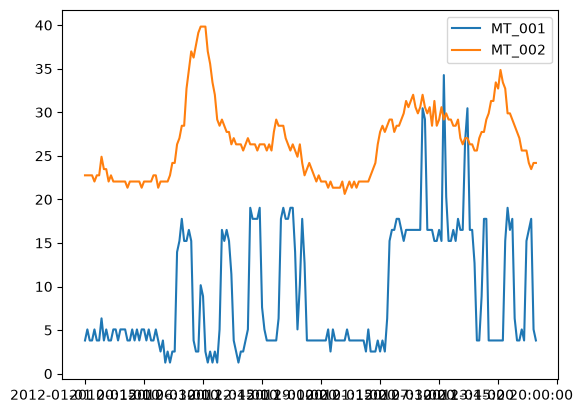

In [3]:
data_example = data.loc['2012-01-01 00:15:00':'2012-01-03 00:00:00'][['MT_001','MT_002']]
data_example.plot()
plt.show()

#### We quickly note that the main difference between the curves is the level (also seen on the means in df.describe()), so we know we will have to somehow normalize the curves, in order for the clustering technique to capture the behaviour of the consumption throughout the day, rather than the overall level.

### Data for the analysis

We focus on 2013 and 2014 because these are the years with lower number of clients having zero demand

In [4]:
# data2011 = data.loc['2011-01-01 00:15:00':'2012-01-01 00:00:00']
# data2012 = data.loc['2012-01-01 00:15:00':'2013-01-01 00:00:00']
data2013 = data.loc['2013-01-01 00:15:00':'2014-01-01 00:00:00']
data2014 = data.loc['2014-01-01 00:15:00':'2015-01-01 00:00:00']

In [5]:
# # Check number of days
# print(data2011.shape[0]/96)
# print(data2012.shape[0]/96)
print(data2013.shape[0]/96)
print(data2014.shape[0]/96)

365.0
365.0


In [6]:
# See number of clients with 0 demand per year
# print(sum(data2011.mean()==0))
# print(sum(data2012.mean()==0))
print(sum(data2013.mean()==0))
print(sum(data2014.mean()==0))

21
1


In [21]:
data2013.columns

Index(['MT_001', 'MT_002', 'MT_003', 'MT_004', 'MT_005', 'MT_006', 'MT_007',
       'MT_008', 'MT_009', 'MT_010',
       ...
       'MT_361', 'MT_362', 'MT_363', 'MT_364', 'MT_365', 'MT_366', 'MT_367',
       'MT_368', 'MT_369', 'MT_370'],
      dtype='str', length=370)

In [7]:
clients_no_demand_2013 = data2013.columns[data2013.mean(axis=0).eq(0)]
data_13 = data2013.drop(columns=clients_no_demand_2013)

clients_no_demand_2014 = data2014.columns[data2014.mean(axis=0).eq(0)]
data_14 = data2014.drop(columns=clients_no_demand_2014)

In [8]:
data_13_14 = pd.concat([data_13, data_14]) # appending 2013 and 2014

print(data_13_14.shape)
print(sum(data_13_14.mean()==0)) # check that there are no clients with 0 demand

(70080, 369)
0


## Getting average curves per client

In [9]:
data = data_13_14.copy() # weekdays weekends, data2011, data2012, data2013, data2014

In [23]:
data.index

Index(['2013-01-01 00:15:00', '2013-01-01 00:30:00', '2013-01-01 00:45:00',
       '2013-01-01 01:00:00', '2013-01-01 01:15:00', '2013-01-01 01:30:00',
       '2013-01-01 01:45:00', '2013-01-01 02:00:00', '2013-01-01 02:15:00',
       '2013-01-01 02:30:00',
       ...
       '2014-12-31 21:45:00', '2014-12-31 22:00:00', '2014-12-31 22:15:00',
       '2014-12-31 22:30:00', '2014-12-31 22:45:00', '2014-12-31 23:00:00',
       '2014-12-31 23:15:00', '2014-12-31 23:30:00', '2014-12-31 23:45:00',
       '2015-01-01 00:00:00'],
      dtype='str', length=70080)

In [25]:
data2013.shape

(35040, 370)

In [26]:
data2014.shape

(35040, 370)

In [10]:
data["hour"] = pd.to_datetime(data.index).hour

In [28]:
data.head(3)

,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,MT_010,...,MT_120,MT_121,MT_122,MT_133,MT_160,MT_178,MT_181,MT_337,MT_347,hour
2013-01-01 00:15:00,2.538071,22.759602,2.606429,138.211382,63.414634,255.952381,4.522329,239.057239,57.692308,78.494624,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2013-01-01 00:30:00,1.269036,22.759602,2.606429,138.211382,63.414634,264.880952,5.652911,228.956229,57.692308,76.344086,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2013-01-01 00:45:00,2.538071,22.759602,2.606429,134.146341,60.975610,250.000000,5.652911,239.057239,54.195804,76.344086,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


### Getting average curves per client

In [11]:
datagrouped = data.groupby("hour")
average_curves = datagrouped.agg("mean")
average_curves.shape 

(24, 369)

#### The dataframe average_curves contains the 369 typical weekday electric demands

#### We now divide each curve by its mean, so that all curves have mean 1

In [12]:
average_curves_norm = average_curves/(average_curves.mean())

#### Plot the first 2 and last 2 clients

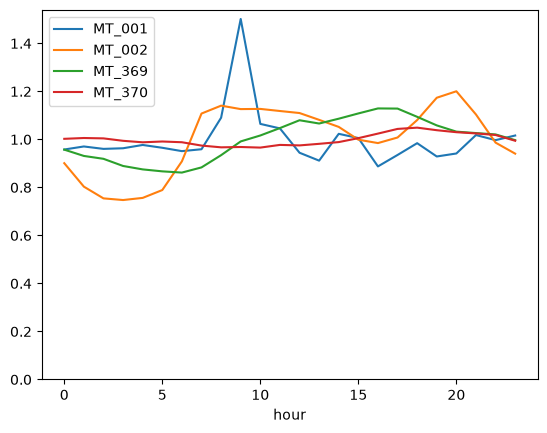

In [13]:
average_curves_norm[['MT_001','MT_002','MT_369','MT_370']].plot()
plt.ylim(bottom=0)
plt.show()

## Clustering Analysis on the average normizalied curves

In [14]:
X = average_curves_norm.copy()
X = np.array(X.T) # put it on the right format

## Exercise 1:

a. Using the functions described in Module 2, determine what a convenient number of clusters based on _intertia_ and based on _silhouette_. Justify your choice

b. Make a plot for each cluster, that includes:
    - The number of clients in the cluster (you can put this in the title of the plot)
    - All the curves in the cluster
    - The curve corresponding to the centroid of the cluster (make this curve thicker to distinguish it from the individual curves)
    
You can do 2 separate plots for each cluster if you prefer (one for the individual curves, one for the centroid)

In [33]:
X[:2]

array([[0.95792709, 0.97056884, 0.96052241, 0.96311774, 0.97684786,
        0.96512703, 0.95114575, 0.95901545, 1.0902888 , 1.5016901 ,
        1.06458668, 1.04583335, 0.94444813, 0.91154607, 1.02322888,
        1.00564763, 0.88751836, 0.93515518, 0.98429897, 0.92887616,
        0.94135048, 1.01812195, 0.99694072, 1.01619638],
       [0.90094427, 0.80320036, 0.7543674 , 0.74745192, 0.75636058,
        0.7890401 , 0.90862235, 1.10769791, 1.14056808, 1.1262085 ,
        1.12700577, 1.1182791 , 1.10982975, 1.08143123, 1.05208813,
        0.99880084, 0.98469258, 1.00791748, 1.0805213 , 1.17349025,
        1.20046753, 1.10381554, 0.9865471 , 0.94065192]])

### Answer to question a.

#### Inertia

In [15]:
# Plot inertia of models from 1 to 10 clusters
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 11)]
inertias = [model.inertia_ for model in kmeans_per_k]

In [16]:
# Find the elbow of the inertia values mathematically

from kneed import KneeLocator

def find_elbow(inertias, k_values=None):
    if k_values is None:
        k_values = range(1, len(inertias) + 1)

    if len(k_values) != len(inertias):
        raise ValueError("k_values and inertias must have the same length.")

    elbow = KneeLocator(
        k_values,
        inertias,
        curve="convex",
        direction="decreasing",
    ).elbow

    return int(elbow) if elbow is not None else None

In [17]:
elbow = find_elbow(inertias)
print(f"{elbow = }")

elbow = 4


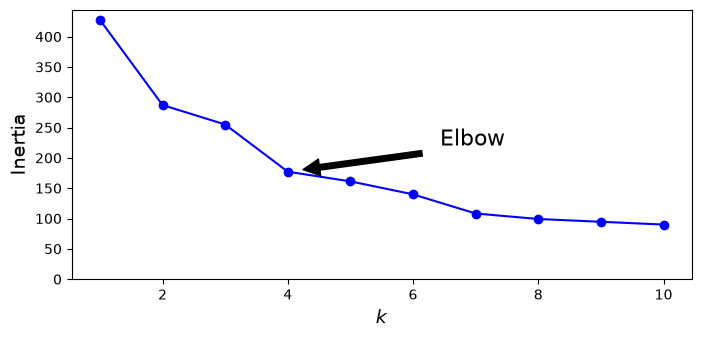

In [18]:
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 11), inertias, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.annotate('Elbow',
             xy=(elbow, inertias[elbow-1]),
             xytext=(0.55, 0.55),
             textcoords='figure fraction',
             fontsize=16,
             arrowprops=dict(facecolor='black', shrink=0.1)
            )
plt.ylim(bottom=0)
plt.show()

Looking at the inertia diagram, it looks like the convenient number of clusters is 4.

However, inertia diagrams can be misleading because inertia has a propensity to go down as k increases. This number can be our baseline.

#### Silhouette diagram

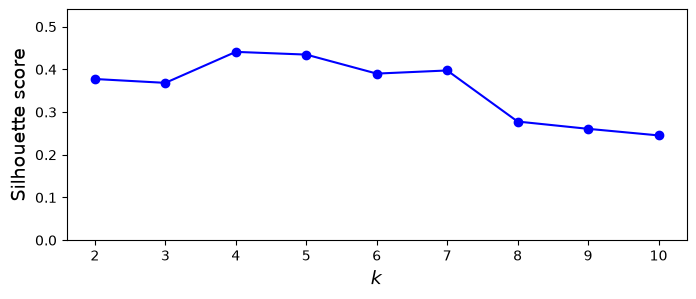

In [19]:
from sklearn.metrics import silhouette_score

def plot_silhouette_scores(X, kmeans_models):
    # Skip k=1; silhouette score requires at least 2 clusters.
    models = kmeans_models[1:]
    k_values = range(2, len(kmeans_models) + 1)
    scores = [silhouette_score(X, model.labels_) for model in models]

    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(k_values, scores, "bo-")
    ax.set_xlabel("$k$", fontsize=14)
    ax.set_ylabel("Silhouette score", fontsize=14)
    ax.set_xticks(k_values)
    ax.set_ylim(bottom=0, top=max(scores) + 0.1)
    plt.show()

    return scores

# Calcualte and plot silhouette scores
silhouette_scores = plot_silhouette_scores(X, kmeans_per_k)

Looks like k = 4 and 5 have the best silhouette scores, which matches with the elbow value k = 4.

Since silhouette score is calcualted by taking into account intra and inter cluster (nearest external cluster) means and calculating 
how close the score is to the maximum of these two means, it is not affected by the number of target clusters. Hence, it is a more
stable scoring criteria.

However, we are still not sure whether to choose k = 4 or k = 5. For this, let's plot a **silhouette diagram**.

In [30]:
# Plot silhouette diagram

from sklearn.metrics import silhouette_samples
from matplotlib.cm import Spectral
import math

def plot_silhouette_diagram(X, kmeans_models, silhouette_scores):
    # Models are indexed by k - 1; skip k=1 because silhouette requires k >= 2.
    k_values = range(2, len(kmeans_models) + 1)
    ncols = 3
    nrows = math.ceil(len(k_values) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(11, 3 * nrows), squeeze=False
    )

    for k, ax in zip(k_values, axes.flat):
        labels = kmeans_models[k - 1].labels_
        coefficients = silhouette_samples(X, labels)

        padding = len(X) // 30
        pos = padding
        ticks = []

        for cluster_id in range(k):
            cluster_coefficients = np.sort(coefficients[labels == cluster_id])
            end = pos + len(cluster_coefficients)

            ax.fill_betweenx(
                np.arange(pos, end),
                0,
                cluster_coefficients,
                facecolor=Spectral(cluster_id / k),
                edgecolor=Spectral(cluster_id / k),
                alpha=0.7,
            )
            ticks.append(pos + len(cluster_coefficients) // 2)
            pos = end + padding

        ax.set_yticks(ticks, labels=range(k))
        ax.axvline(silhouette_scores[k - 2], color="red", linestyle="--")
        ax.set_title(f"$k={k}$", fontsize=16)

        if k in (3, 5):
            ax.set_ylabel("Cluster")

    # Hide any unused subplot slots.
    for ax in axes.flat[len(k_values):]:
        ax.set_visible(False)

    fig.subplots_adjust(hspace=0.5)
    plt.show()
    return fig, axes

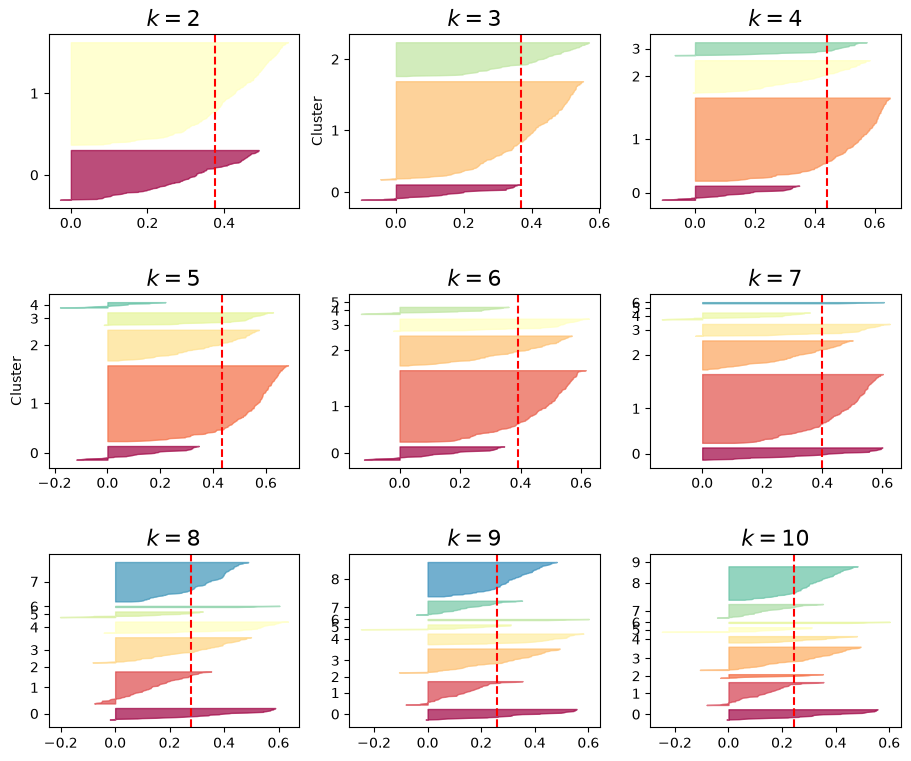

(<Figure size 1100x900 with 9 Axes>,
 array([[<Axes: title={'center': '$k=2$'}>,
         <Axes: title={'center': '$k=3$'}, ylabel='Cluster'>,
         <Axes: title={'center': '$k=4$'}>],
        [<Axes: title={'center': '$k=5$'}, ylabel='Cluster'>,
         <Axes: title={'center': '$k=6$'}>,
         <Axes: title={'center': '$k=7$'}>],
        [<Axes: title={'center': '$k=8$'}>,
         <Axes: title={'center': '$k=9$'}>,
         <Axes: title={'center': '$k=10$'}>]], dtype=object))

In [31]:
plot_silhouette_diagram(X, kmeans_per_k, silhouette_scores)

Interestingly, while k = 4 and 5 are not the best candidates because one or more of their clusters's score is lower than the mean silhouette coeffecient of all clusters.

**k = 8 looks the most promising** because all of its cluster widths not only go past its mean silhouette coeffecient, but also the thin clusters #5 and #6 seems to have captured the anomalies.

k = 9 seems to show a similar characteristic but it has a smaller silhouette score than k = 8. So, we'll stick to k = 8.

k = 2 and 3 also does not look bad on paper. We will also take them into consideration and compare all the plots to find the best k.

Let's perform some statistical analysis on the standard deviation for values for each client to confirm if there are outliers in the data. To do this, we can separate the standard deviations of each client's energy usage across the 24 hours and check if there are clients who show a very small or large standard deviation. For example, a large std can be a lone commercial client among residential clients having a much higher peak usage during the day.

In [32]:
# Separate standard deviations of the clients and look at its spread
client_std = average_curves_norm.std(axis=0)
client_std.describe()

count    369.000000
mean       0.293734
std        0.136454
min        0.016177
25%        0.226038
50%        0.270831
75%        0.330805
max        1.264350
dtype: float64

In [33]:
# Find how many sample are near 16% (sigma = 2) of the minimum and maximum standard deviation
# *Using the bell curve's 16%-68%-16% spread property

span = client_std.max() - client_std.min()
tolerance = 0.16 * span

near_min = client_std <= client_std.min() + tolerance
near_max = client_std >= client_std.max() - tolerance

print("Clients near minimum:", near_min.sum())
print("Clients near maximum:", near_max.sum())

Clients near minimum: 76
Clients near maximum: 1


Looks like we have at least one anomaly!

Let's use k = 8 as our target cluster size. We will also compare it with k = 3 and k = 5.

k = 3 is its potential contender, whereas k = 5 should show us what a suboptimal clustering would look like in comparison. 

### Answer to question b.


 Make a plot for each cluster, that includes:
    
    
    - The number of clients in the cluster (you can put this in the title of the plot)

    - All the curves in the cluster

    - The curve corresponding to the centroid of the cluster (make this curve thicker to distinguish it from the individual curves)
    
    - You can do 2 separate plots for each cluster if you prefer (one for the individual curves, one for the centroid)

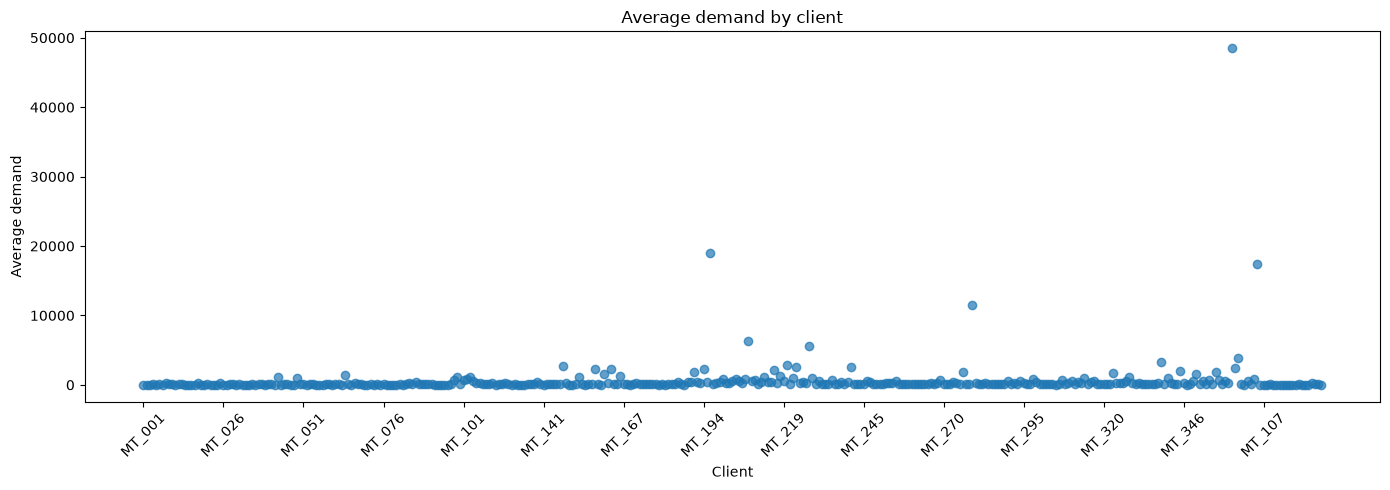

In [34]:
# Visualize average demand by client
# We are not using normalized values to visualize because the value compression make visualization unintuitive

usage = average_curves.mean(axis=0)  # one average-demand value per client
x = np.arange(len(usage))

plt.figure(figsize=(14, 5))
plt.scatter(usage.index, usage.values, alpha=0.7)
plt.xticks(x[::25], usage.index[::25], rotation=45)
plt.xlabel("Client")
plt.ylabel("Average demand")
plt.title("Average demand by client")
plt.tight_layout()
plt.show()

Looks like the anomalies are masking the usage patterns of other clients.  

#### Plot curves in each cluster (k = 8)

In [85]:
def plot_cluster_curves(
    X,
    model,
    x_label="Hour of day",
    y_label="Normalized demand",
    group_label="clients",
    xtick_step=2,
    xtick_divisor=1,
):
    if xtick_step <= 0 or xtick_divisor <= 0:
        raise ValueError("xtick_step and xtick_divisor must be positive.")

    X = np.asarray(X)
    labels = model.labels_
    x_values = np.arange(X.shape[1])
    plots = []

    for cluster_id in range(model.n_clusters):
        curves = X[labels == cluster_id]
        fig, ax = plt.subplots(figsize=(10, 5))

        for curve in curves:
            ax.plot(x_values, curve, color="steelblue", alpha=0.2, linewidth=0.8)

        ax.plot(
            x_values,
            model.cluster_centers_[cluster_id],
            color="black",
            linewidth=3,
            label="Centroid",
        )

        tick_positions = x_values[::xtick_step]
        tick_labels = [f"{x / xtick_divisor:g}" for x in tick_positions]

        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels)
        ax.set(
            title=f"Cluster {cluster_id + 1} — {len(curves)} {group_label}",
            xlabel=x_label,
            ylabel=y_label,
        )
        ax.legend()
        ax.grid(alpha=0.2)
        fig.tight_layout()
        plots.append((fig, ax))

    plt.show()
    return plots

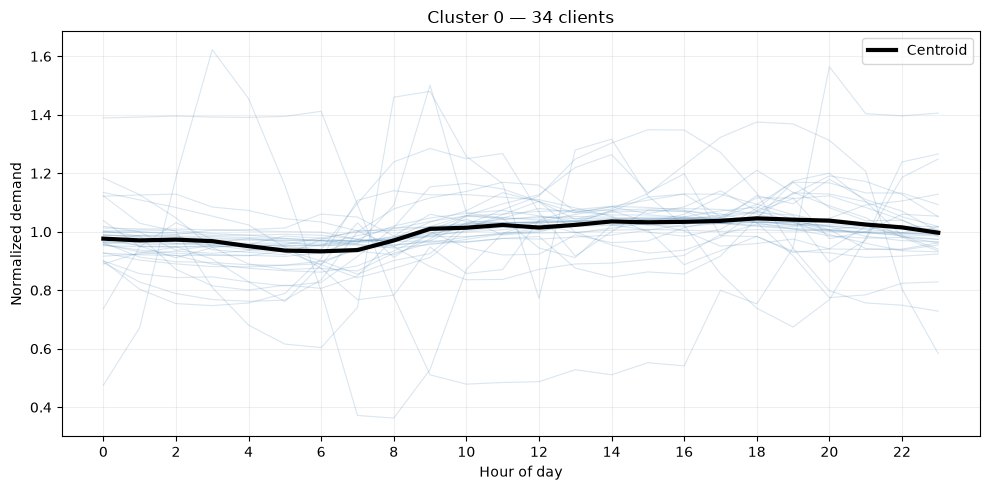

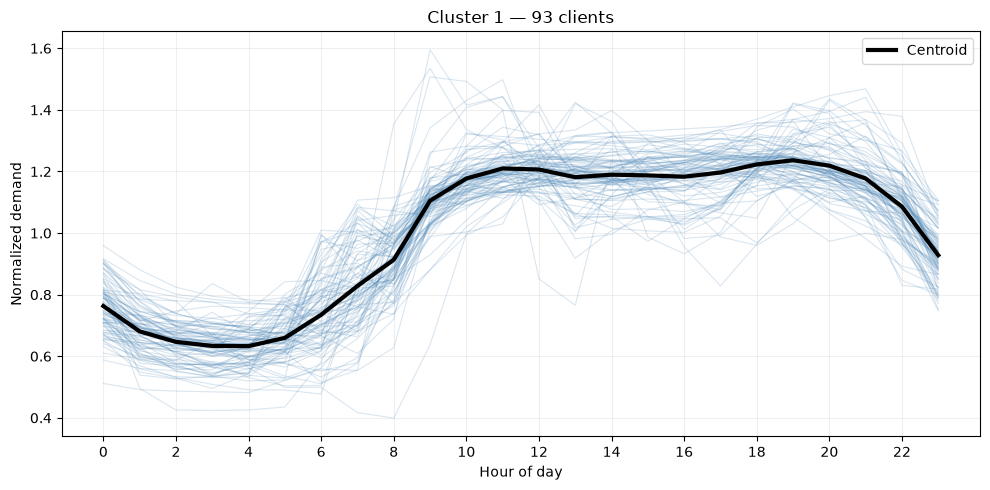

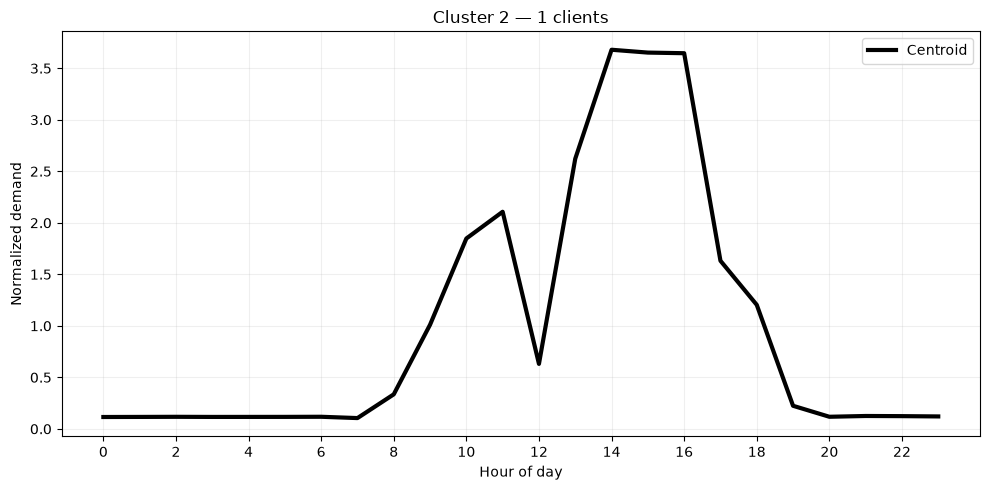

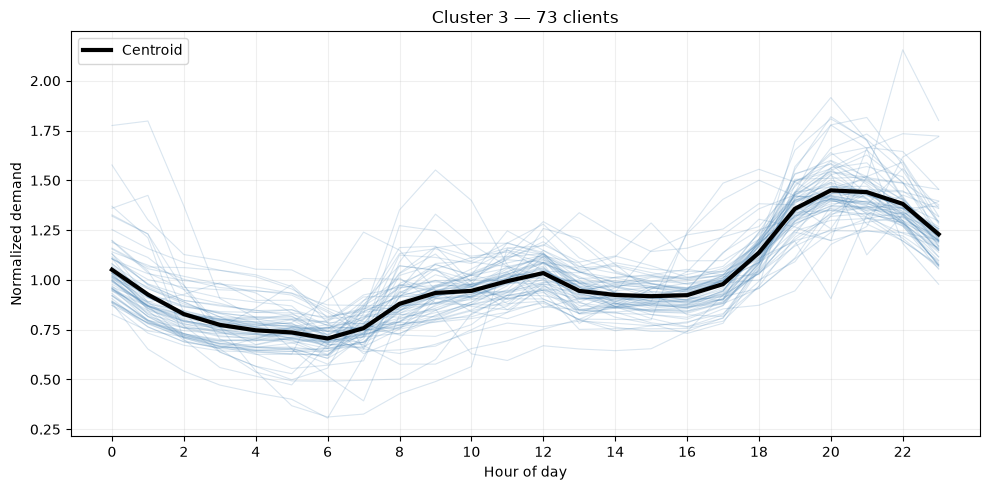

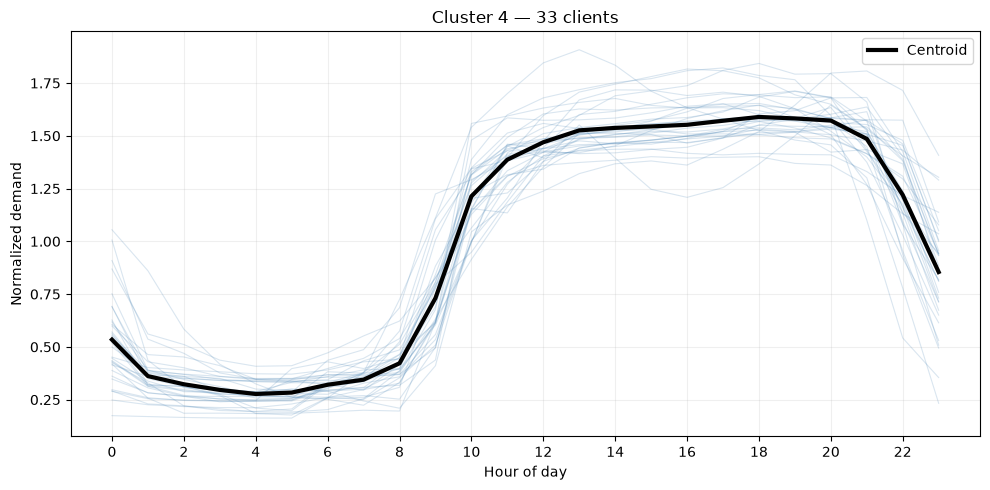

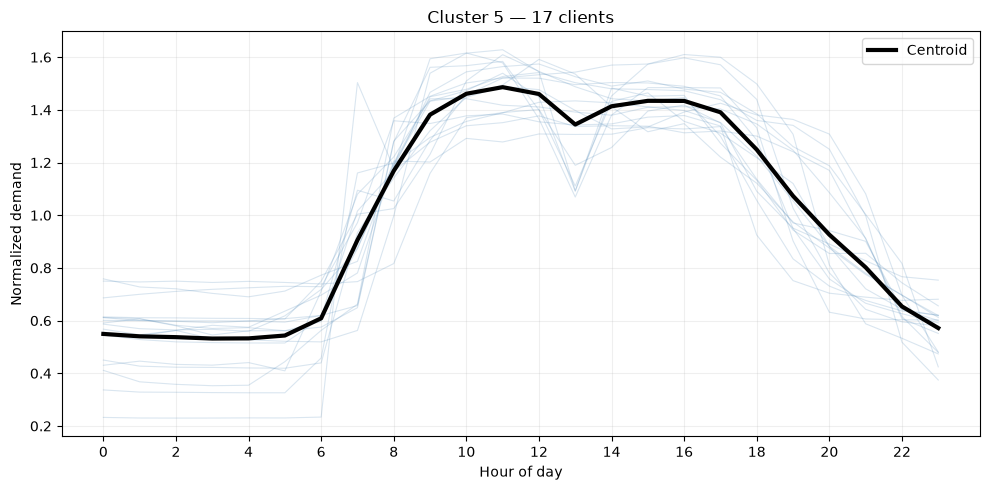

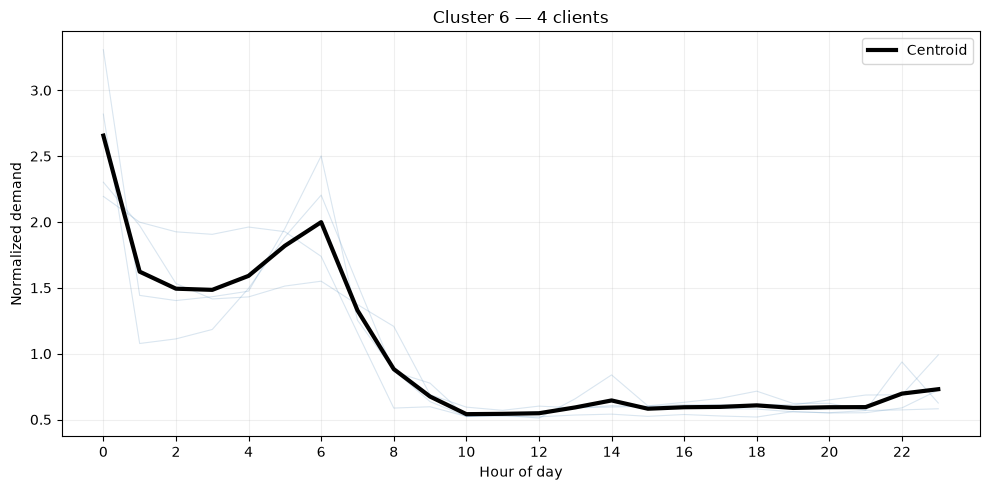

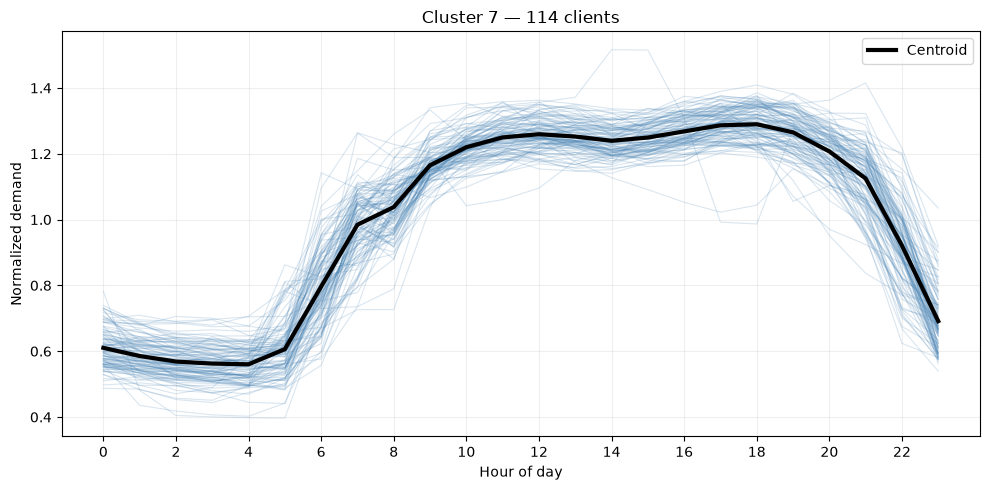

In [35]:
k = 8
plot_cluster_curves(X, kmeans_per_k[k - 1])

A more interesting visualization would be to **superimpose** the clusters with their centres on a single plot.

#### Superimpose cluster plots so check whether they are well separated or not
Here, we will compare k = 8 with k = 3 and k = 5

In [58]:
def plot_cluster_profiles(
    X,
    model,
    x_label="Hour of day",
    y_label="Normalized demand",
    group_label="clients",
    xtick_step=2,
):
    X = np.asarray(X)
    labels = model.labels_
    n_clusters = model.n_clusters
    x_values = np.arange(X.shape[1])
    colors = plt.cm.tab10(np.arange(n_clusters))

    fig, ax = plt.subplots(figsize=(11, 6))

    for cluster_id in range(n_clusters):
        curves = X[labels == cluster_id]
        color = colors[cluster_id]

        for curve in curves:
            ax.plot(x_values, curve, color=color, alpha=0.15, linewidth=0.8)

        ax.plot(
            x_values,
            model.cluster_centers_[cluster_id],
            color=color,
            linewidth=3,
            label=f"Cluster {cluster_id + 1} ({len(curves)} {group_label})",
        )

    ax.set(
        title=f"{group_label.capitalize()} demand profiles by cluster",
        xlabel=x_label,
        ylabel=y_label,
        xticks=x_values[::xtick_step],
    )
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

    return fig, ax

In [38]:
k_3, k_5, k_8 = 3, 5, 8

##### k = 3

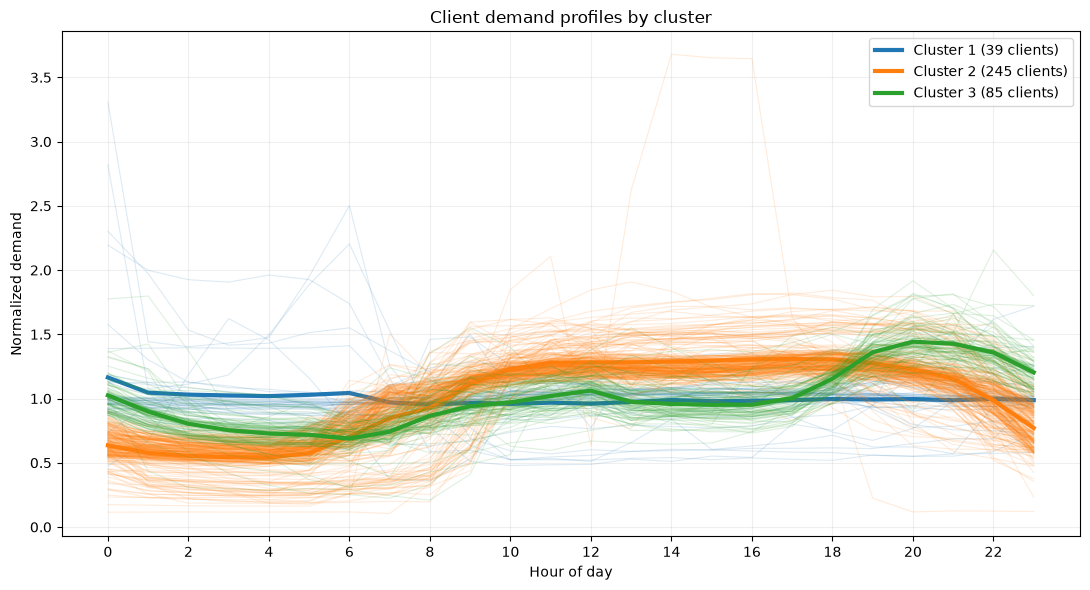

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Client demand profiles by cluster'}, xlabel='Hour of day', ylabel='Normalized demand'>)

In [39]:
plot_cluster_profiles(X, kmeans_per_k[k_3 - 1])

##### k = 5

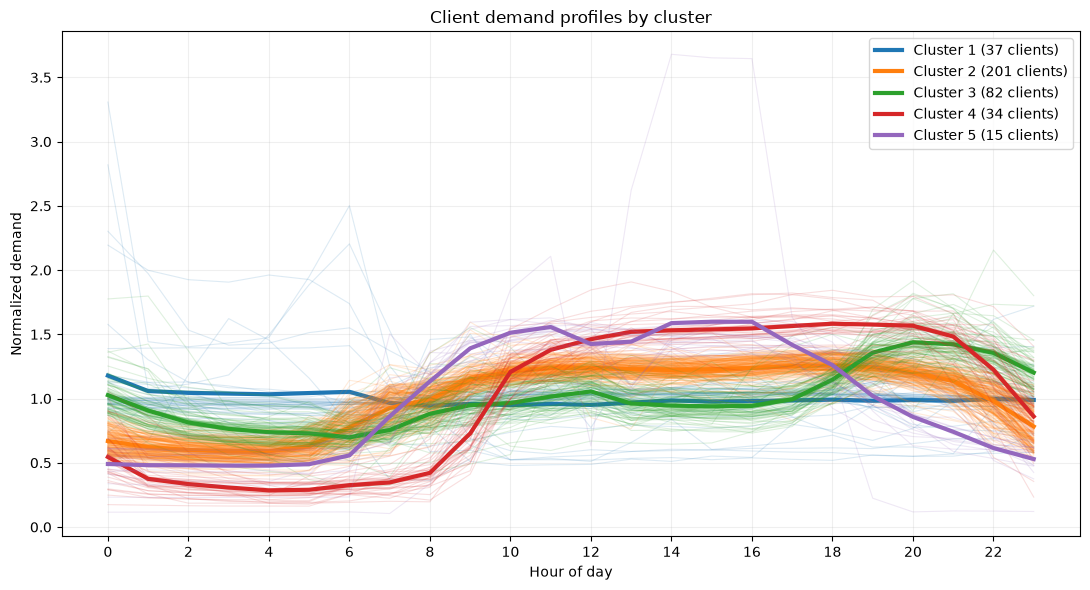

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Client demand profiles by cluster'}, xlabel='Hour of day', ylabel='Normalized demand'>)

In [40]:
plot_cluster_profiles(X, kmeans_per_k[k_5 - 1])

##### k = 8

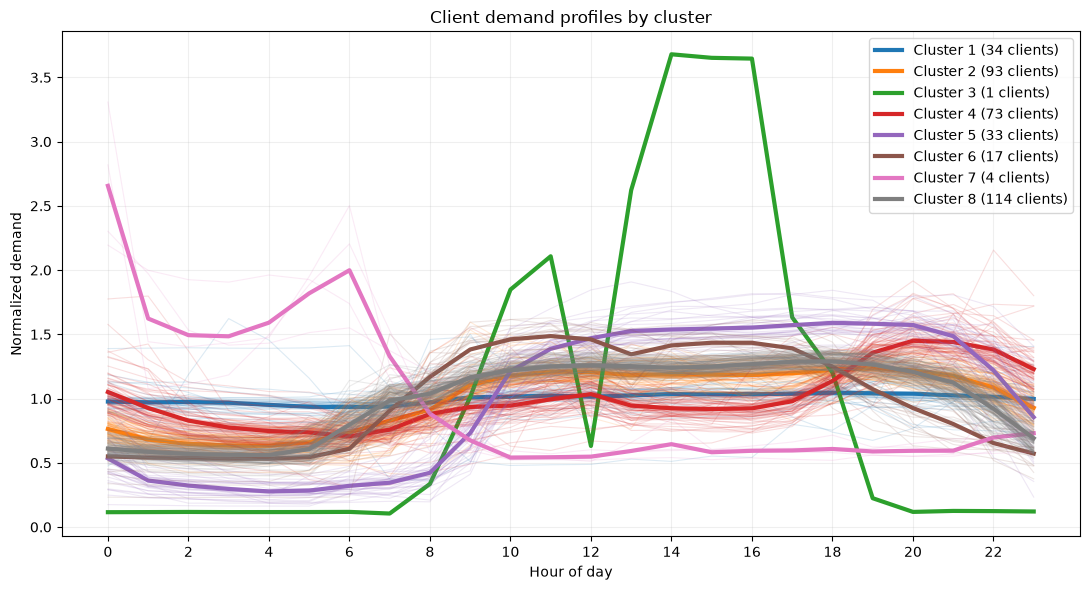

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Client demand profiles by cluster'}, xlabel='Hour of day', ylabel='Normalized demand'>)

In [41]:
plot_cluster_profiles(X, kmeans_per_k[k_8 - 1])

### Verdict
It is clear that k = 8 is the most convenient number of clusters to explain variations in energy demand.

- Clusters 3 and 7 clearly capture anomalies, which lie on different end of the spectrum.

- Clients in cluster 7 had peak energy consumption starting at midnight and lasting until 6 am.

- The lone client in cluster 3 uses the most amount of energy during the day, which may incicate it is probably a commercial client whose work starts at 7 am and ends at 7 pm.

- The rest of the clusters show different energy consumption signatures although their duration of consumption overlaps.

## Exercises 2

In this exercise you work with the daily curves of 1 single client.

First you create a list of arrays, each array containing a normalized curve for a day. The list contains 730 arrays, one for each of the days of 2013 and 2014.

a. Determine the optimal value for k-means. 

b. What are the clusters that you obtained represent?

### Answer to question a.

In [42]:
client = 'MT_022'
oneClient = data_13_14[client]
X = [] # a list of arrays, each array being a normalized curve for a day
for J in range(2*365):
    # X.extend([np.array(oneClient[J*96:(J+1)*96])]/np.mean(oneClient[J*96:(J+1)*96]))
    curve = np.array(oneClient[J * 96:(J + 1) * 96])
    try:
        X.append(curve / curve.mean())
    except:
        raise ZeroDivisionError(f"Cannot divide by zero. Index {J = }")

In [43]:
np.shape(X)

(730, 96)

### K-means

In [44]:
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 11)]

### Inertia

In [45]:
# Plot inertia of models from 1 to 10 clusters
inertias = [model.inertia_ for model in kmeans_per_k]

In [46]:
# Find elbow
elbow = find_elbow(inertias)
print(f"{elbow = }")

elbow = 2


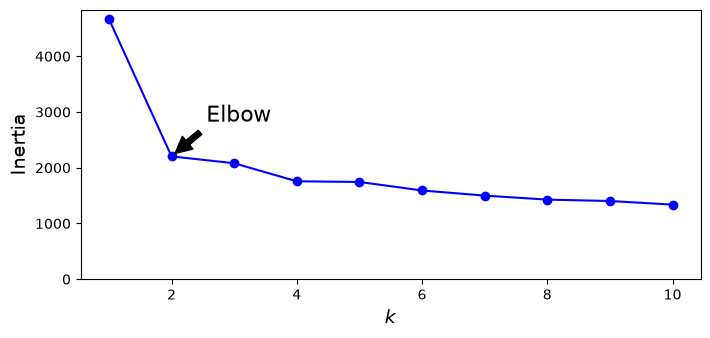

In [47]:
# Plot inertia
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 11), inertias, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.annotate('Elbow',
             xy=(elbow, inertias[elbow - 1]),
             xytext=(25, 25),
             textcoords='offset points',
             fontsize=16,
             arrowprops=dict(facecolor='black', shrink=0.1)
            )
plt.ylim(bottom=0)
plt.show()

#### Silhouette diagram

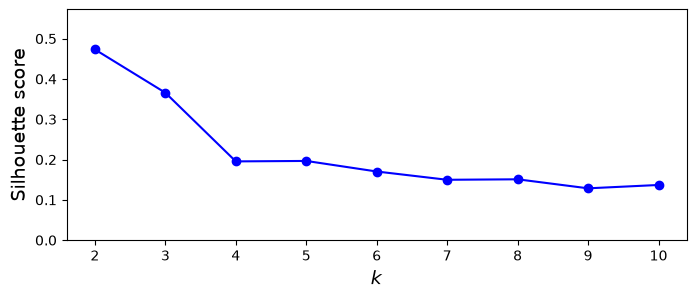

In [48]:
# Calcualte and plot silhouette scores
silhouette_scores = plot_silhouette_scores(X, kmeans_per_k)

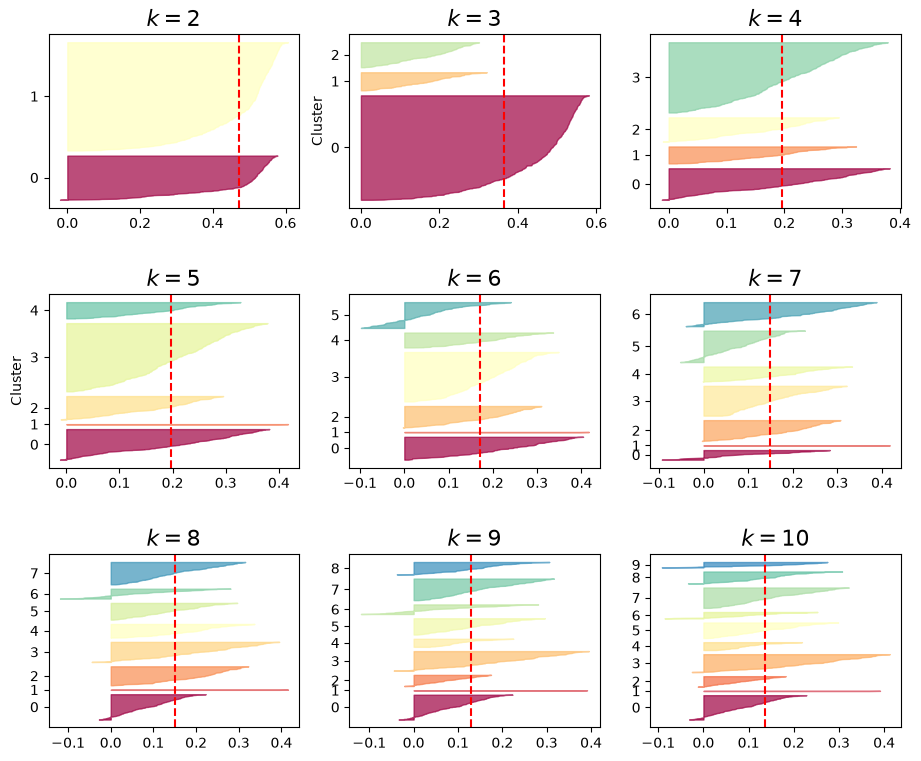

(<Figure size 1100x900 with 9 Axes>,
 array([[<Axes: title={'center': '$k=2$'}>,
         <Axes: title={'center': '$k=3$'}, ylabel='Cluster'>,
         <Axes: title={'center': '$k=4$'}>],
        [<Axes: title={'center': '$k=5$'}, ylabel='Cluster'>,
         <Axes: title={'center': '$k=6$'}>,
         <Axes: title={'center': '$k=7$'}>],
        [<Axes: title={'center': '$k=8$'}>,
         <Axes: title={'center': '$k=9$'}>,
         <Axes: title={'center': '$k=10$'}>]], dtype=object))

In [49]:
plot_silhouette_diagram(X, kmeans_per_k, silhouette_scores)

Looks like k = 2 has a reasonable spread of samples (days) across its clusters. The silhouette shapes have decent heights and they are wide.

However, k = 5 shows more diversity in cluster samples. Their per cluster silhouette scores are also much higher than their mean silhouette coefficient. In addition, it seems to have captured some anomalies in cluster 1.

k = 8 also shows wide shapes. However, its shapes are thin, which might indicate over clustering.

Lets generate superimposition plots for these three models to find out which one is the best.

#### Superimpose daily curves across all clusters (k = 2, 4, 5, 8)
Discussion provided below after the plots

In [74]:
k_2, k_5, k_8 = 2, 5, 8

##### k = 2

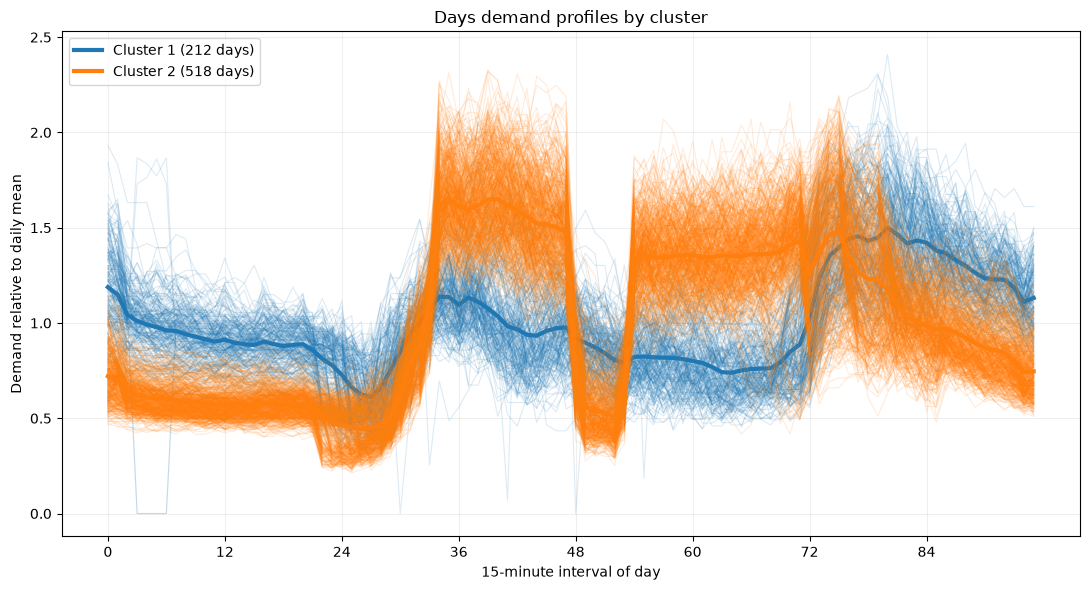

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Days demand profiles by cluster'}, xlabel='15-minute interval of day', ylabel='Demand relative to daily mean'>)

In [71]:
plot_cluster_profiles(
    X,
    kmeans_per_k[k_2 - 1],
    x_label="15-minute interval of day",
    y_label="Demand relative to daily mean",
    group_label="days",
    xtick_step=12,
)

##### k = 5

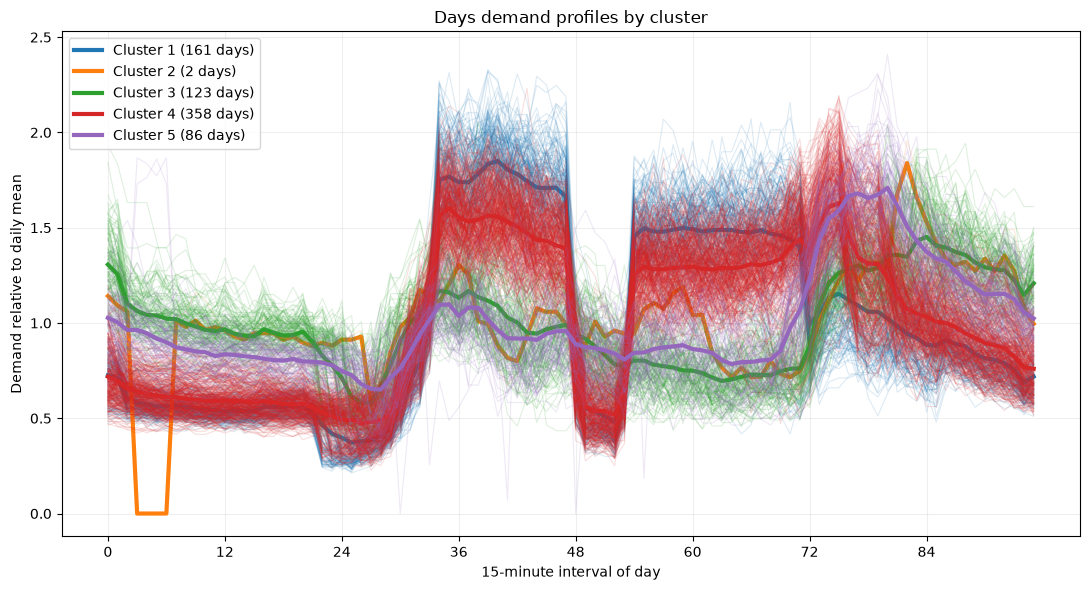

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Days demand profiles by cluster'}, xlabel='15-minute interval of day', ylabel='Demand relative to daily mean'>)

In [73]:
plot_cluster_profiles(
    X,
    kmeans_per_k[k_5 - 1],
    x_label="15-minute interval of day",
    y_label="Demand relative to daily mean",
    group_label="days",
    xtick_step=12,
)

##### k = 8

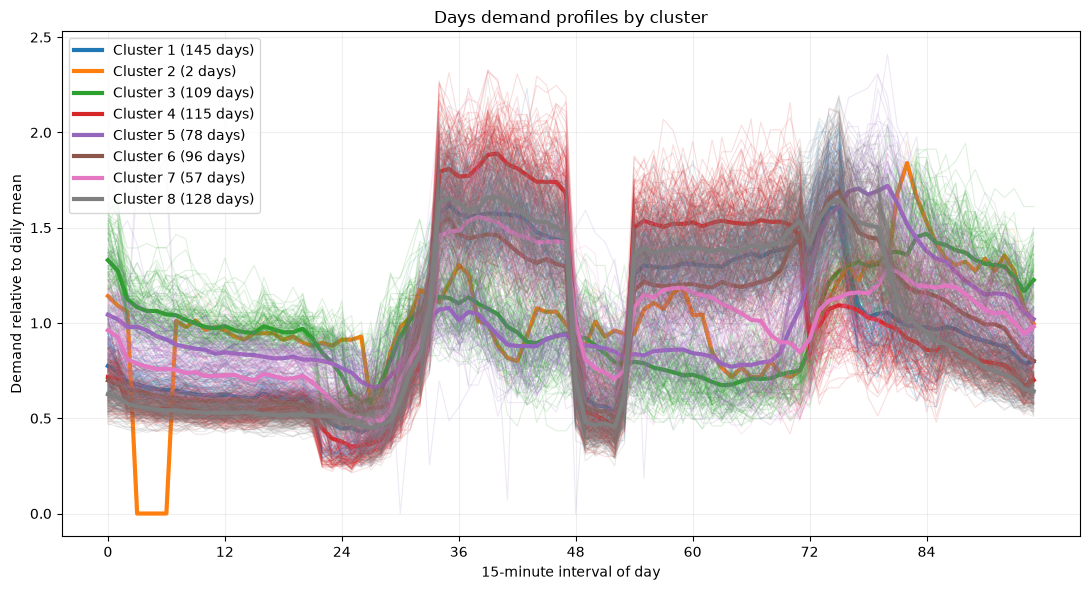

(<Figure size 1100x600 with 1 Axes>,
 <Axes: title={'center': 'Days demand profiles by cluster'}, xlabel='15-minute interval of day', ylabel='Demand relative to daily mean'>)

In [68]:
plot_cluster_profiles(
    X,
    kmeans_per_k[k_8 - 1],
    x_label="15-minute interval of day",
    y_label="Demand relative to daily mean",
    group_label="days",
    xtick_step=12,
)

### Discussion
Over the course of 2 years:

k = 2 shows two distinct usage pattern throghout the day for the client. However, it does not capture the one anomalous day where usage dropped to zero from 1 am to 2 am. It could have been a power outage.

k = 5 and 8 are able to capture that anomaly. However, it looks like they are showing a similar usage pattern than k = 2 is showing, but separated into more groups. It looks redundant.

If we ignore the anomalous day, then k = 2 is clearly the best model as it perfectlty captures the client's energy usage patterns throughout the day.

### Answer to question b.
Let's plot the daily curves per cluster for k = 2 to check out the curves in the two clusters separately.

#### Plot daily curves per cluster, k = 2

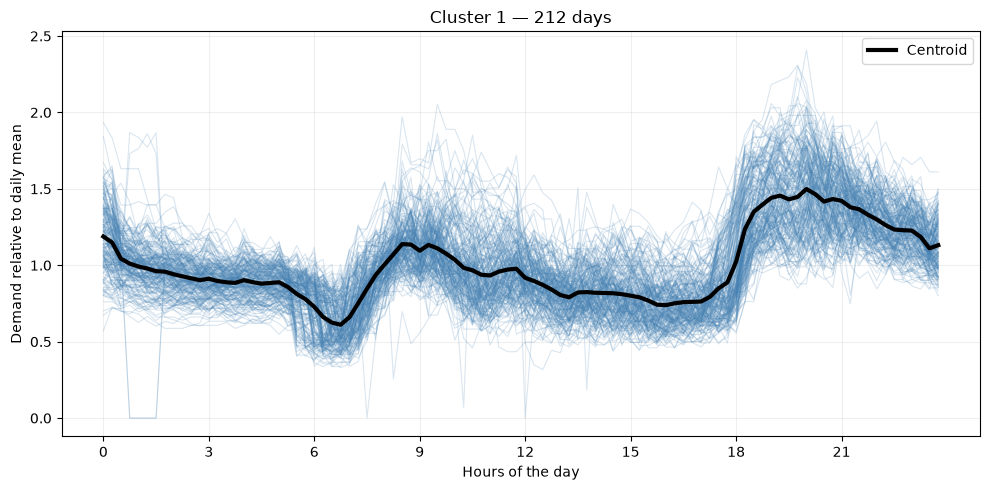

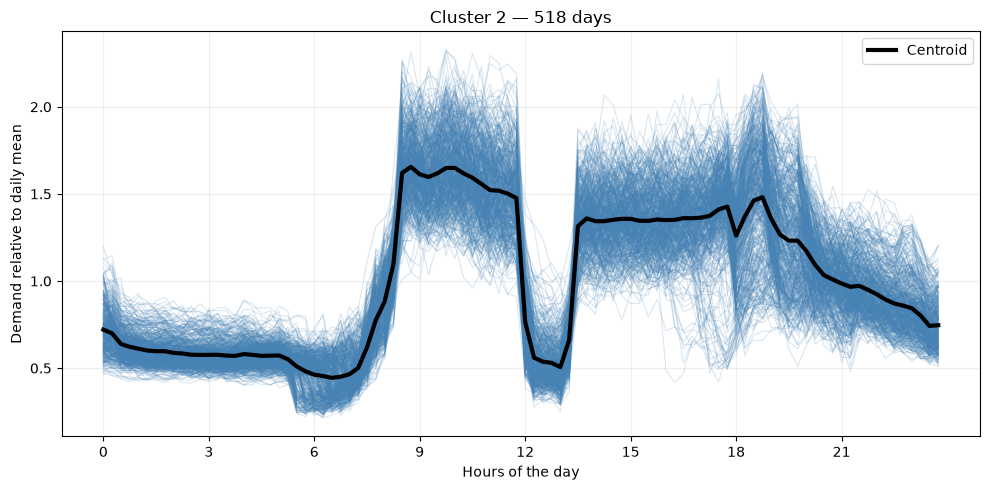

[(<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 1 — 212 days'}, xlabel='Hours of the day', ylabel='Demand relative to daily mean'>),
 (<Figure size 1000x500 with 1 Axes>,
  <Axes: title={'center': 'Cluster 2 — 518 days'}, xlabel='Hours of the day', ylabel='Demand relative to daily mean'>)]

In [88]:
X = np.asarray(X)

plot_cluster_curves(
    X,
    kmeans_per_k[k_2 - 1],
    x_label="Hours of the day",
    y_label="Demand relative to daily mean",
    group_label="days",
    xtick_step=12,
    xtick_divisor=4
)

#### The following cell generates a list of all the days in the two years 2013-2014, which is helpful to answer part (b)

In [76]:
from datetime import date, timedelta

d1 = date(2013, 1, 1)  # start date
d2 = date(2014, 12, 31)  # end date
delta = d2 - d1         # timedelta
daysyear = []
D = {0:'mon', 1:'tue', 2:'wed', 3:'thu', 4:'fri', 5:'sat', 6:'sun'}
for i in range(delta.days + 1):
    daysyear.extend([D[(d1 + timedelta(days=i)).weekday()]+"-"+str(d1 + timedelta(days=i))])

#### The following cell shows you how to do the following: given a list L, and a list of booleans B (True, False), get the sublist of L that corresponds to the True values in B. For example if L=[1,2,3,4] and B=[False,True,True,False], then the results is [2,3]. This is also helpful for part (b)

In [417]:
from itertools import compress
L = [1,2,3,4]
B = [False, True, True, False]
list(compress(L, B))

[2, 3]

In [89]:
from itertools import compress

model = kmeans_per_k[k_2 - 1]  # the model fitted on the 730 daily curves
labels = model.labels_

weekdays = [day.split("-")[0] for day in daysyear]
weekday_order = ["mon", "tue", "wed", "thu", "fri", "sat", "sun"]

for cluster_id in range(model.n_clusters):
    in_cluster = labels == cluster_id

    cluster_days = list(compress(daysyear, in_cluster))
    weekday_counts = (
        pd.Series([weekdays[i] for i in range(len(weekdays)) if in_cluster[i]])
        .value_counts()
        .reindex(weekday_order, fill_value=0)
    )

    print(f"\nCluster {cluster_id+1} — {len(cluster_days)} days")
    print(weekday_counts)


Cluster 1 — 212 days
mon     13
tue     11
wed     10
thu     11
fri     11
sat     52
sun    104
Name: count, dtype: int64

Cluster 2 — 518 days
mon    91
tue    94
wed    95
thu    93
fri    93
sat    52
sun     0
Name: count, dtype: int64


### Discussion
It is clear that cluster 1 represents off days or non-working days and cluster 2 represents working days.

A big hint is cluster 2 does not have any Sunday in it, and half the number of Saturdays compared to the number of Saturdays there can be in 2 years.

Looking at the curves in the clusters, it becomes clearer. In cluster 2 (working days), demand is lower than the daily mean from midnight until 6 am. From 6 am, it start peaking, which the peak being from 9 to 12. Then, there is a 1-hour dip which can be explained by a lunch break. Then demand peaks again and sustains until 7 pm before tapering off.

There is an interesting dip at 6 pm that looks more like an oscilation, but I am unable to explain it.

Cluster 1 shows a typical non-working day pattern where the demand stays near the daily mean with a spike around 8 am to 9 am and another spike around 6 pm which starts tapering off at 9, which is closer to bedtime.